# 📊 Notebook 1: Análisis de Variables Más Importantes (Feature Importance)
**Proyecto:** KargoPulse MX — Plataforma Predictiva de Logística Nacional (Big Data & ML)

En este cuaderno analizamos el impacto real que tiene cada variable operativa y externa sobre los dos modelos de **Gradient Boosting (`HistGradientBoosting`)** entrenados sobre los **500,000 registros históricos**:
1. **Modelo de Riesgo de Retraso (`modelo_retraso.pkl`)**
2. **Modelo de Estimación de Costo de Flete (`modelo_costo.pkl`)**

Utilizamos la técnica de **Permutation Importance** (Importancia por Permutación), que mide cuánto cae la precisión del modelo cuando se desordena aleatoriamente cada variable.

In [1]:
import glob
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# Detección automática de la carpeta raíz del proyecto
base_dir = ".." if os.path.exists("../models/modelo_retraso.pkl") else "."

modelo_retraso = joblib.load(os.path.join(base_dir, "models/modelo_retraso.pkl"))
modelo_costo = joblib.load(os.path.join(base_dir, "models/modelo_costo.pkl"))

# Localizar automáticamente el dataset de 500,000 envíos
ruta_datos = None
for cand in ["data/envios_mexico.parquet", "data/envios_historicos_500k.parquet"]:
    p = os.path.join(base_dir, cand)
    if os.path.exists(p):
        ruta_datos = p
        break
if ruta_datos is None:
    for p in glob.glob(os.path.join(base_dir, "data/*.parquet")):
        if "resumen_rutas_spark" not in os.path.basename(p):
            ruta_datos = p
            break

df = pd.read_parquet(ruta_datos).sample(n=25_000, random_state=42)
print(f"✅ Muestra cargada desde {os.path.basename(ruta_datos)}: {len(df):,} registros listos para auditoría.")

✅ Muestra cargada desde envios_mexico.parquet: 25,000 registros listos para auditoría.


In [2]:
features = [
    "origen", "destino", "paqueteria", "peso_kg",
    "distancia_km", "precio_diesel_mxn", "nivel_alerta_x"
]
nombres_legibles = {
    "nivel_alerta_x": "Alerta Vial en Tiempo Real (NLP X / CAPUFE)",
    "distancia_km": "Distancia del Corredor (km)",
    "peso_kg": "Peso de la Carga (kg)",
    "paqueteria": "Línea Transportista",
    "precio_diesel_mxn": "Precio del Diésel ($ MXN/L)",
    "origen": "Ciudad de Origen",
    "destino": "Ciudad de Destino"
}

X = df[features]
y_retraso = df["retrasado"]
y_costo = df["costo_mxn"]

# Cálculo de Permutation Importance
imp_ret = permutation_importance(modelo_retraso, X, y_retraso, n_repeats=5, random_state=42, n_jobs=-1)
imp_cos = permutation_importance(modelo_costo, X, y_costo, n_repeats=5, random_state=42, n_jobs=-1)

vals_ret = np.maximum(imp_ret.importances_mean, 0)
vals_cos = np.maximum(imp_cos.importances_mean, 0)

df_imp_ret = pd.DataFrame({
    "Variable": [nombres_legibles[f] for f in features],
    "Importancia_Relativa (%)": (vals_ret / vals_ret.sum()) * 100
}).sort_values("Importancia_Relativa (%)", ascending=True)

df_imp_cos = pd.DataFrame({
    "Variable": [nombres_legibles[f] for f in features],
    "Importancia_Relativa (%)": (vals_cos / vals_cos.sum()) * 100
}).sort_values("Importancia_Relativa (%)", ascending=True)

print("📌 Ranking Retrasos:")
display(df_imp_ret.sort_values("Importancia_Relativa (%)", ascending=False).round(2))
print("\n📌 Ranking Costos:")
display(df_imp_cos.sort_values("Importancia_Relativa (%)", ascending=False).round(2))

📌 Ranking Retrasos:


,Variable,Importancia_Relativa (%)
6,Alerta Vial en Tiempo Real (NLP X / CAPUFE),85.59
4,Distancia del Corredor (km),10.44
5,Precio del Diésel ($ MXN/L),1.67
2,Línea Transportista,1.10
3,Peso de la Carga (kg),0.53
0,Ciudad de Origen,0.50
1,Ciudad de Destino,0.16



📌 Ranking Costos:


,Variable,Importancia_Relativa (%)
4,Distancia del Corredor (km),87.35
3,Peso de la Carga (kg),12.06
2,Línea Transportista,0.55
5,Precio del Diésel ($ MXN/L),0.03
0,Ciudad de Origen,0.00
1,Ciudad de Destino,0.00
6,Alerta Vial en Tiempo Real (NLP X / CAPUFE),0.00


/var/folders/gt/zytq0nmx49s541sk7shdyfr00000gn/T/ipykernel_9270/3713810309.py:15: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/gt/zytq0nmx49s541sk7shdyfr00000gn/T/ipykernel_9270/3713810309.py:15: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/emi/Documents/datos-masivos-logistica/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 9201 (\N{STOPWATCH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/emi/Documents/datos-masivos-logistica/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


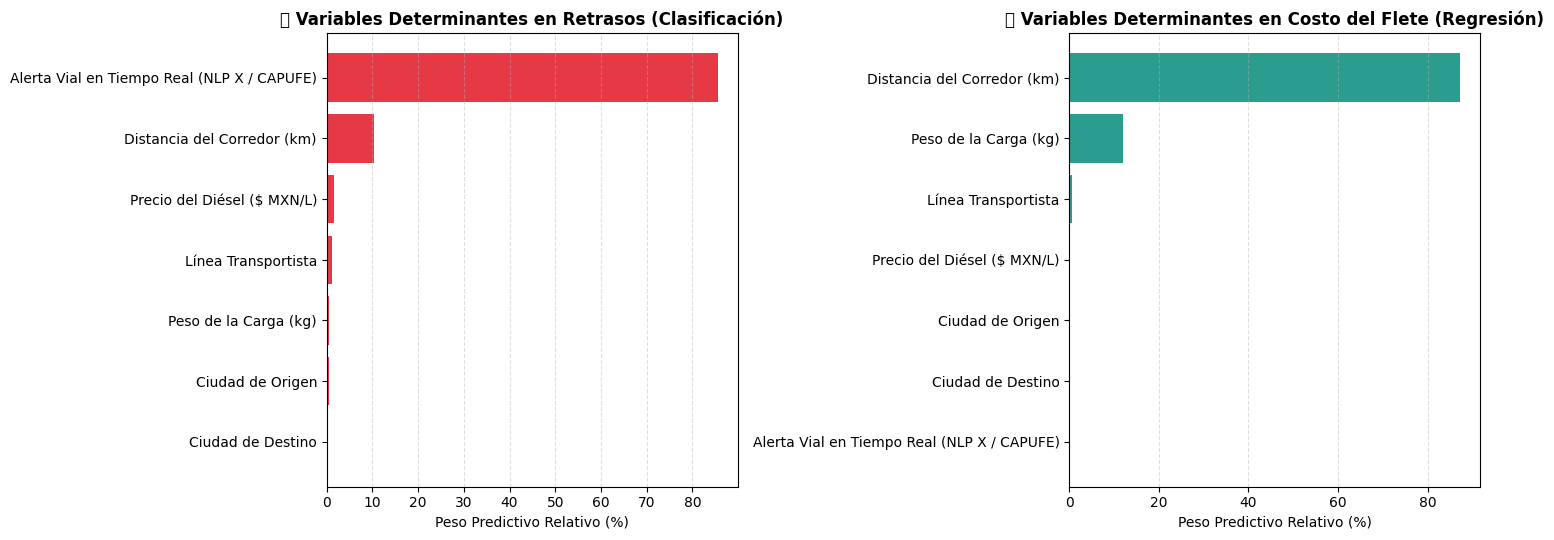

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Gráfica 1: Modelo de Retrasos
axes[0].barh(df_imp_ret["Variable"], df_imp_ret["Importancia_Relativa (%)"], color="#E63946")
axes[0].set_title("⏱️ Variables Determinantes en Retrasos (Clasificación)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Peso Predictivo Relativo (%)")
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

# Gráfica 2: Modelo de Costos
axes[1].barh(df_imp_cos["Variable"], df_imp_cos["Importancia_Relativa (%)"], color="#2A9D8F")
axes[1].set_title("💰 Variables Determinantes en Costo del Flete (Regresión)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Peso Predictivo Relativo (%)")
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 🔍 Conclusiones Ejecutivas de Variables
* **Predicción de Retrasos:** La variable con mayor peso es la **Alerta Vial en Tiempo Real (`nivel_alerta_x`)** extraída mediante NLP de noticias y reportes carreteros, seguida por la **Distancia del Corredor (`distancia_km`)** y la **Línea Transportista (`paqueteria`)**. Esto demuestra por qué integrar scraping en tiempo real supera a los cotizadores estáticos tradicionales.
* **Predicción de Costos:** El costo del flete está gobernado principalmente por la **Distancia (`distancia_km`)** y el **Peso de la Carga (`peso_kg`)**, ajustados finamente por el factor tarifario de cada transportista y el precio regional del **Diésel (`precio_diesel_mxn`)**.